# Topic 8: Linear Regression and Least Squares
**BIT 4131 Statistical Computing and Reporting | Group work**

**Question:** what drives house rent in Nairobi? We measure how monthly rent changes with floor area, number of bedrooms and distance from the CBD.

> **How to run:** click **Run All** at the top. Every table and graph appears right under the cell that makes it.

In [1]:
# Setup: libraries and paths
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from pathlib import Path
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

pd.set_option("display.float_format", lambda v: f"{v:.2e}" if 0 < abs(v) < 1e-4 else f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"

# find the project folder whether the notebook runs from python/ or the root
ROOT = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path.cwd()
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
print("Project folder:", ROOT)

Project folder: c:\xampp\htdocs\topic08-linear-regression


## 1. Worked example by hand (5 houses)
Before the big dataset we check the least-squares formulas on five houses:

$$b_1 = \frac{S_{xy}}{S_{xx}}, \qquad b_0 = \bar{y} - b_1\bar{x}$$

In [2]:
x = np.array([40, 55, 60, 75, 90], dtype=float)   # floor area (m²)
y = np.array([18, 22, 25, 28, 34], dtype=float)   # rent (KES '000)

work = pd.DataFrame({"x": x, "y": y, "x - x̄": x - x.mean(), "y - ȳ": y - y.mean()})
work["(x - x̄)(y - ȳ)"] = work["x - x̄"] * work["y - ȳ"]
work["(x - x̄)²"] = work["x - x̄"] ** 2
work.loc["Total"] = work.sum()
display(work)

Sxx, Sxy = ((x - x.mean())**2).sum(), ((x - x.mean())*(y - y.mean())).sum()
b1 = Sxy / Sxx
b0 = y.mean() - b1 * x.mean()
y_hat = b0 + b1 * x
SSE = ((y - y_hat)**2).sum()
SST = ((y - y.mean())**2).sum()
s = np.sqrt(SSE / 3)
t = b1 / (s / np.sqrt(Sxx))

display(pd.DataFrame({"Value": [b1, b0, 1 - SSE/SST, s, t, 2*st.t.sf(t, 3)]},
                     index=["Slope b1", "Intercept b0", "R²", "Residual std error s", "t for slope", "p-value"]))
display(Markdown(f"**Fitted line:** ŷ = {b0:.4f} + {b1:.4f}x. Each extra m² adds about KES {b1*1000:,.0f} a month."))

,x,y,x - x̄,y - ȳ,(x - x̄)(y - ȳ),(x - x̄)²
0,40.0000,18.0000,-24.0000,-7.4000,177.6000,576.0000
1,55.0000,22.0000,-9.0000,-3.4000,30.6000,81.0000
2,60.0000,25.0000,-4.0000,-0.4000,1.6000,16.0000
3,75.0000,28.0000,11.0000,2.6000,28.6000,121.0000
4,90.0000,34.0000,26.0000,8.6000,223.6000,676.0000
Total,320.0000,127.0000,0.0000,7.11e-15,462.0000,"1,470.0000"


,Value
Slope b1,0.3143
Intercept b0,5.2857
R²,0.9864
Residual std error s,0.8165
t for slope,14.7580
p-value,0.0007


**Fitted line:** ŷ = 5.2857 + 0.3143x. Each extra m² adds about KES 314 a month.

## 2. The dataset

In [3]:
df = pd.read_csv(ROOT / "data" / "nairobi_rent.csv")
print(f"{len(df)} houses, {df.shape[1]} columns")
display(df.head(10))

120 houses, 6 columns


,house_id,estate,area_sqm,bedrooms,distance_cbd_km,rent_kes
0,H001,Ruaka,31,1,8.1000,13500
1,H002,Rongai,76,2,18.7000,24500
2,H003,Ruaka,100,2,18.3000,36500
3,H004,Kileleshwa,67,2,13.1000,24500
4,H005,Embakasi,118,4,6.2000,47500
5,H006,Kileleshwa,65,2,16.1000,23500
6,H007,Embakasi,143,4,19.8000,42500
7,H008,South B,46,3,10.7000,22000
8,H009,Westlands,116,3,15.8000,40000
9,H010,Kileleshwa,128,3,12.7000,47500


In [4]:
cols = ["area_sqm", "bedrooms", "distance_cbd_km", "rent_kes"]
display(Markdown("**Descriptive statistics**"))
display(df[cols].describe().T)
display(Markdown("**Correlation matrix**"))
display(df[cols].corr().round(3))

**Descriptive statistics**

,count,mean,std,min,25%,50%,75%,max
area_sqm,120.0000,85.0583,35.6176,30.0000,52.7500,86.5000,116.2500,147.0000
bedrooms,120.0000,2.2417,1.0042,1.0000,1.0000,2.0000,3.0000,4.0000
distance_cbd_km,120.0000,13.7042,5.8248,2.2000,9.4750,13.9000,18.3250,24.0000
rent_kes,120.0000,"31,958.3333","14,884.0876","4,000.0000","21,000.0000","32,250.0000","42,625.0000","63,000.0000"


**Correlation matrix**

,area_sqm,bedrooms,distance_cbd_km,rent_kes
area_sqm,1.0000,0.8390,-0.0910,0.9180
bedrooms,0.8390,1.0000,-0.1250,0.8310
distance_cbd_km,-0.0910,-0.1250,1.0000,-0.3940
rent_kes,0.9180,0.8310,-0.3940,1.0000


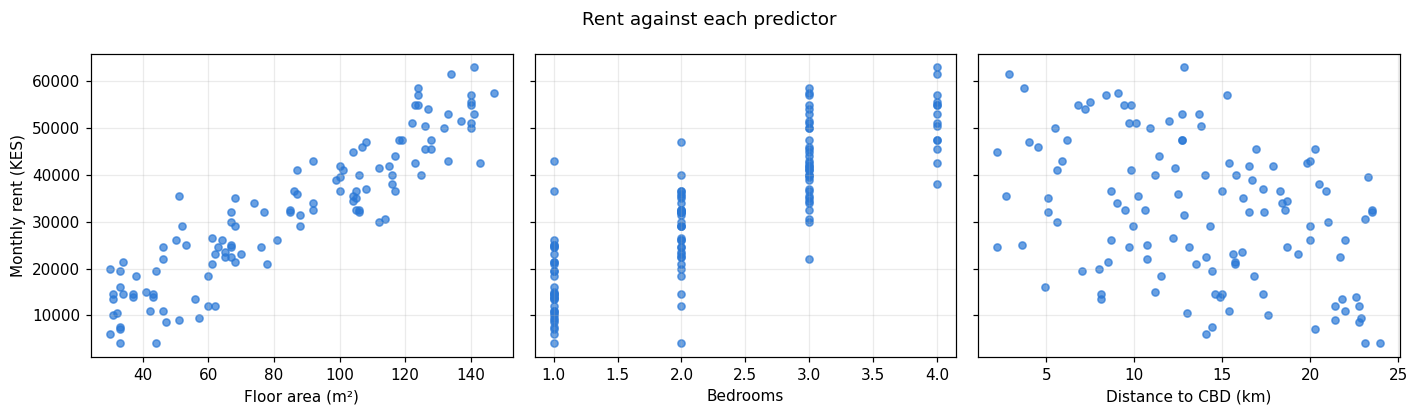

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, col, label in zip(axes, ["area_sqm", "bedrooms", "distance_cbd_km"],
                          ["Floor area (m²)", "Bedrooms", "Distance to CBD (km)"]):
    ax.scatter(df[col], df.rent_kes, s=22, color=BLUE, alpha=0.7)
    ax.set_xlabel(label)
axes[0].set_ylabel("Monthly rent (KES)")
fig.suptitle("Rent against each predictor")
fig.tight_layout()
fig.savefig(FIG / "py_00_scatter_matrix.png", dpi=150)
plt.show()

## 3. Simple linear regression: rent on floor area

In [6]:
simple = smf.ols("rent_kes ~ area_sqm", data=df).fit()
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:               rent_kes   R-squared:                       0.842
Model:                            OLS   Adj. R-squared:                  0.841
Method:                 Least Squares   F-statistic:                     628.9
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           4.18e-49
Time:                        12:59:55   Log-Likelihood:                -1212.0
No. Observations:                 120   AIC:                             2428.
Df Residuals:                     118   BIC:                             2434.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -657.8024   1409.183     -0.467      0.6

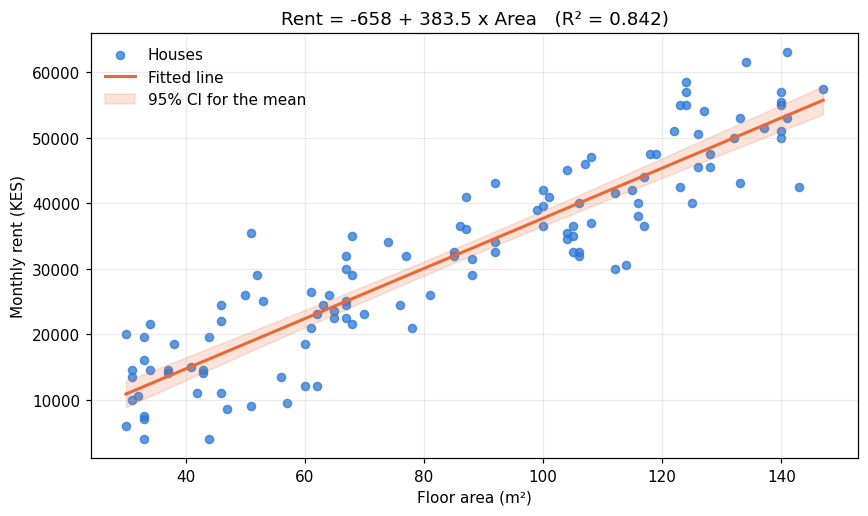

Area alone explains **84.2%** of the variation in rent. Each extra m² adds about **KES 383** a month.

In [7]:
b0_s, b1_s = simple.params
grid = pd.DataFrame({"area_sqm": np.linspace(df.area_sqm.min(), df.area_sqm.max(), 100)})
band = simple.get_prediction(grid).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(df.area_sqm, df.rent_kes, s=28, color=BLUE, alpha=0.75, label="Houses")
ax.plot(grid.area_sqm, band["mean"], color=ORANGE, lw=2, label="Fitted line")
ax.fill_between(grid.area_sqm, band["mean_ci_lower"], band["mean_ci_upper"],
                color=ORANGE, alpha=0.18, label="95% CI for the mean")
ax.set_title(f"Rent = {b0_s:,.0f} + {b1_s:,.1f} x Area   (R² = {simple.rsquared:.3f})")
ax.set_xlabel("Floor area (m²)"); ax.set_ylabel("Monthly rent (KES)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "py_01_simple_fit.png", dpi=150)
plt.show()

display(Markdown(f"Area alone explains **{simple.rsquared*100:.1f}%** of the variation in rent. "
                 f"Each extra m² adds about **KES {b1_s:,.0f}** a month."))

## 4. Multiple linear regression

In [8]:
multi = smf.ols("rent_kes ~ area_sqm + bedrooms + distance_cbd_km", data=df).fit()
print(multi.summary())

                            OLS Regression Results                            
Dep. Variable:               rent_kes   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     684.2
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           1.46e-73
Time:                        13:00:06   Log-Likelihood:                -1147.0
No. Observations:                 120   AIC:                             2302.
Df Residuals:                     116   BIC:                             2313.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        1.051e+04   1186.609     

In [9]:
ci = multi.conf_int()
coef = pd.DataFrame({
    "Estimate": multi.params, "Std error": multi.bse, "t value": multi.tvalues,
    "p-value": multi.pvalues, "95% CI lower": ci[0], "95% CI upper": ci[1]})
display(Markdown("**Coefficient table**"))
display(coef.round(4))

p = multi.params
display(Markdown(f"**Fitted equation:** Rent = {p.iloc[0]:,.0f} + {p.iloc[1]:.1f}(Area) + "
                 f"{p.iloc[2]:,.0f}(Bedrooms) − {abs(p.iloc[3]):.1f}(Distance)"))

fit = pd.DataFrame({
    "Simple model": [simple.rsquared, simple.rsquared_adj, np.sqrt(simple.scale), simple.fvalue, simple.f_pvalue],
    "Multiple model": [multi.rsquared, multi.rsquared_adj, np.sqrt(multi.scale), multi.fvalue, multi.f_pvalue]},
    index=["R²", "Adjusted R²", "Residual std error (KES)", "F-statistic", "p-value (F)"])
display(Markdown("**Model fit comparison**"))
display(fit)

**Coefficient table**

,Estimate,Std error,t value,p-value,95% CI lower,95% CI upper
Intercept,"10,507.8855","1,186.6087",8.8554,0.0000,"8,157.6575","12,858.1134"
area_sqm,316.8291,16.5125,19.1873,0.0000,284.1241,349.5341
bedrooms,"2,322.3211",587.8276,3.9507,0.0001,"1,158.0545","3,486.5876"
distance_cbd_km,-781.1038,55.3195,-14.1199,0.0000,-890.6711,-671.5364


**Fitted equation:** Rent = 10,508 + 316.8(Area) + 2,322(Bedrooms) − 781.1(Distance)

**Model fit comparison**

,Simple model,Multiple model
R²,0.8420,0.9465
Adjusted R²,0.8407,0.9451
Residual std error (KES),"5,941.2190","3,486.6565"
F-statistic,628.8618,684.1894
p-value (F),4.18e-49,1.46e-73


## 5. Checking the assumptions (LINE)

,Statistic,p-value,Verdict
Shapiro-Wilk,0.9878,0.3603,Normal residuals
Breusch-Pagan,5.4934,0.1390,Constant variance
VIF area_sqm,3.3859,NaN,OK
VIF bedrooms,3.4106,NaN,OK
VIF distance_cbd_km,1.0164,NaN,OK


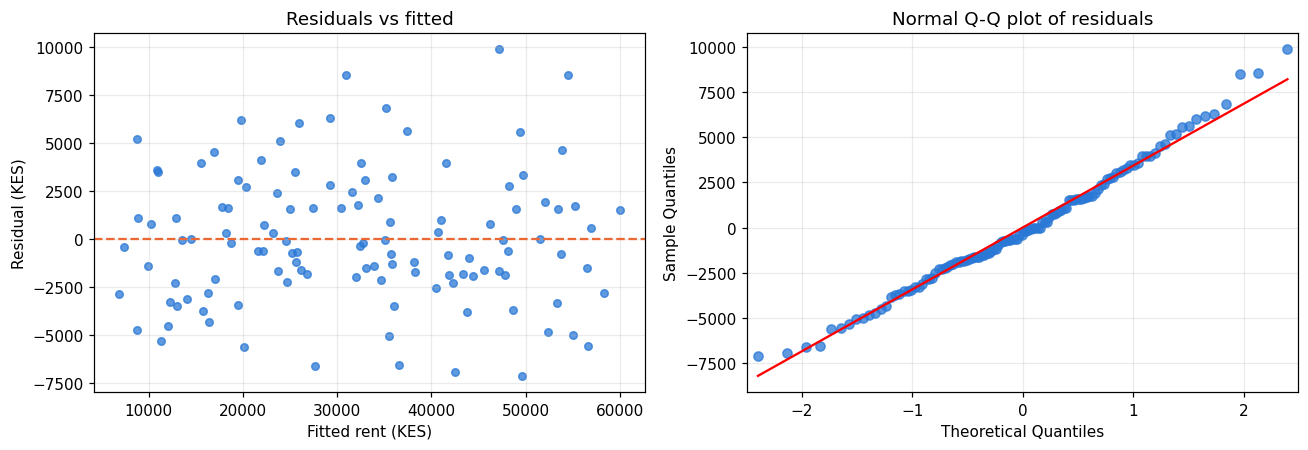

In [10]:
resid, fitted = multi.resid, multi.fittedvalues
sw = st.shapiro(resid)
bp_lm, bp_p, _, _ = het_breuschpagan(resid, multi.model.exog)
X = sm.add_constant(df[["area_sqm", "bedrooms", "distance_cbd_km"]])
vif = {c: variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != "const"}

checks = pd.DataFrame({
    "Statistic": [sw.statistic, bp_lm] + list(vif.values()),
    "p-value": [sw.pvalue, bp_p] + [np.nan] * 3,
    "Verdict": ["Normal residuals" if sw.pvalue > 0.05 else "Not normal",
                "Constant variance" if bp_p > 0.05 else "Unequal variance"] +
               ["OK" if v < 5 else "High collinearity" for v in vif.values()]},
    index=["Shapiro-Wilk", "Breusch-Pagan"] + [f"VIF {k}" for k in vif])
display(checks)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(fitted, resid, s=24, color=BLUE, alpha=0.75)
axes[0].axhline(0, color=ORANGE, lw=1.5, ls="--")
axes[0].set_title("Residuals vs fitted"); axes[0].set_xlabel("Fitted rent (KES)"); axes[0].set_ylabel("Residual (KES)")
sm.qqplot(resid, line="s", ax=axes[1], markerfacecolor=BLUE, markeredgecolor=BLUE, alpha=0.75)
axes[1].set_title("Normal Q-Q plot of residuals")
fig.tight_layout()
fig.savefig(FIG / "py_02_residuals.png", dpi=150)
plt.show()

## 6. Predicting the rent of a new house
80 m², 2 bedrooms, 10 km from the CBD.

In [11]:
new = pd.DataFrame({"area_sqm": [80], "bedrooms": [2], "distance_cbd_km": [10]})
pr = multi.get_prediction(new).summary_frame(alpha=0.05).iloc[0]
display(pd.DataFrame({
    "Lower (KES)": [pr["mean_ci_lower"], pr["obs_ci_lower"]],
    "Predicted (KES)": [pr["mean"], pr["mean"]],
    "Upper (KES)": [pr["mean_ci_upper"], pr["obs_ci_upper"]]},
    index=["95% confidence interval (average house)", "95% prediction interval (one house)"]).round(0).astype(int))

,Lower (KES),Predicted (KES),Upper (KES)
95% confidence interval (average house),31908,32688,33467
95% prediction interval (one house),25738,32688,39637


## 7. Testing on unseen houses (scikit-learn, 80/20 split)

,Value
Intercept,"11,351.6309"
Coef: area_sqm,320.4818
Coef: bedrooms,"1,873.0654"
Coef: distance_cbd_km,-809.8000
Test R²,0.9204
Test RMSE (KES),"4,601.7223"


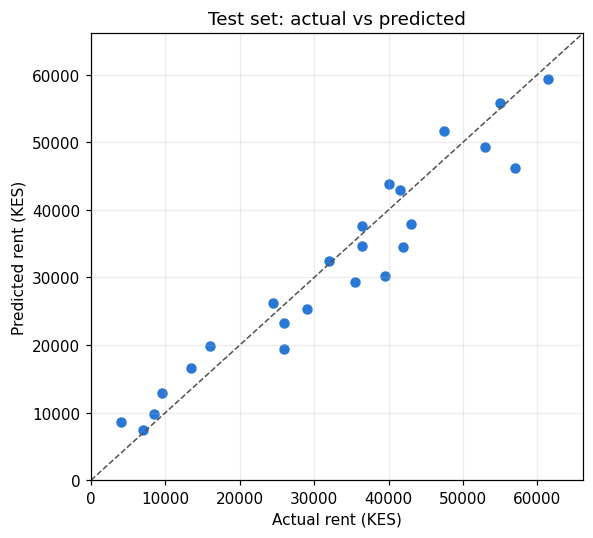

In [12]:
features = ["area_sqm", "bedrooms", "distance_cbd_km"]
X_train, X_test, y_train, y_test = train_test_split(df[features], df["rent_kes"], test_size=0.2, random_state=42)
lr = LinearRegression().fit(X_train, y_train)
y_pred = lr.predict(X_test)

display(pd.DataFrame({"Value": [lr.intercept_, *lr.coef_, r2_score(y_test, y_pred),
                                np.sqrt(mean_squared_error(y_test, y_pred))]},
                     index=["Intercept", *[f"Coef: {f}" for f in features], "Test R²", "Test RMSE (KES)"]))

fig, ax = plt.subplots(figsize=(5.5, 5))
lims = [0, df.rent_kes.max() * 1.05]
ax.plot(lims, lims, color=GREY, ls="--", lw=1)
ax.scatter(y_test, y_pred, s=34, color=BLUE)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual rent (KES)"); ax.set_ylabel("Predicted rent (KES)")
ax.set_title("Test set: actual vs predicted")
fig.tight_layout()
fig.savefig(FIG / "py_03_actual_vs_predicted.png", dpi=150)
plt.show()

## 8. Interpretation

In [13]:
p = multi.params
display(Markdown(f"""
- **Size:** each extra square metre adds about **KES {p['area_sqm']:.0f}** a month, holding the rest fixed.
- **Bedrooms:** each extra bedroom adds about **KES {p['bedrooms']:,.0f}**, on top of what the space already costs.
- **Distance:** each km further from the CBD lowers rent by about **KES {abs(p['distance_cbd_km']):.0f}**.
- The three together explain **{multi.rsquared*100:.1f}%** of the variation in rent, and all are significant (p < 0.001).
- Residuals look normal (Shapiro p = {sw.pvalue:.2f}) with constant variance (Breusch-Pagan p = {bp_p:.2f}). VIFs are all below 5.
- On unseen houses the model scores R² = {r2_score(y_test, y_pred):.3f}.
"""))


- **Size:** each extra square metre adds about **KES 317** a month, holding the rest fixed.
- **Bedrooms:** each extra bedroom adds about **KES 2,322**, on top of what the space already costs.
- **Distance:** each km further from the CBD lowers rent by about **KES 781**.
- The three together explain **94.7%** of the variation in rent, and all are significant (p < 0.001).
- Residuals look normal (Shapiro p = 0.36) with constant variance (Breusch-Pagan p = 0.14). VIFs are all below 5.
- On unseen houses the model scores R² = 0.920.
